# Enterprise Data Visualization & Storytelling: Superstore Sales
**Final Project: Database Knowledge Extraction**

**Business question:** The business is growing and profitable, but *where are we losing money?*

Notebook outline: 1) Setup, 2) Load & inspect, 3) Cleaning, 4) Distributions & uncertainty, 5) X-Y relationships, 6) Key insights.

## 1. Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

warnings.filterwarnings("ignore")      # keep the notebook output clean
os.makedirs("outputs", exist_ok=True)  # folder for exported charts

sns.set_theme(style="white")           # clean style, no gridlines (decluttering)
GREY, BLUE, ORANGE = "#9aa0a6", "#2a788e", "#d95f02"  # colorblind-safe accents

## 2. Load and inspect the data

In [2]:
# The file uses latin-1 encoding
df = pd.read_csv("data/superstore.csv", encoding="latin-1")

# Standardize column names (spaces and hyphens -> underscores)
df.columns = df.columns.str.strip().str.replace(" ", "_").str.replace("-", "_")

print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicated rows:", df.duplicated().sum())
df.head()

Shape: (9994, 21)

Missing values per column:
 Row_ID           0
Order_ID         0
Order_Date       0
Ship_Date        0
Ship_Mode        0
Customer_ID      0
Customer_Name    0
Segment          0
Country          0
City             0
State            0
Postal_Code      0
Region           0
Product_ID       0
Category         0
Sub_Category     0
Product_Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicated rows: 0


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,...,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Data cleaning and feature engineering

In [3]:
# 1. Remove duplicates (none expected, but we verify)
df = df.drop_duplicates()

# 2. Convert date columns to datetime
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"])

# 3. Impute missing values: median for numeric, "Unknown" for text
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].fillna("Unknown")

# 4. New features
df["Year"] = df["Order_Date"].dt.year
df["Month_Start"] = df["Order_Date"].dt.to_period("M").dt.to_timestamp()
df["Profit_Margin"] = df["Profit"] / df["Sales"]
df["Discount_Band"] = pd.cut(
    df["Discount"], bins=[-0.01, 0, 0.2, 0.4, 1],
    labels=["0%", "1-20%", "21-40%", ">40%"]
)

# Save the clean dataset (used by the BI dashboard)
df.to_csv("data/superstore_clean.csv", index=False)
print("Clean rows:", len(df))

Clean rows: 9994


## 4. Distributions and uncertainty

### 4.1 Histogram + KDE of profit per order
Most orders earn small profits, but there is a long tail of losses.

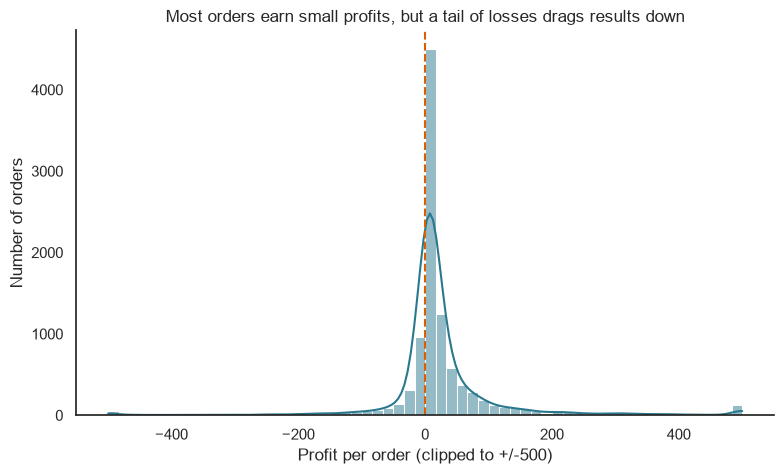

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df["Profit"].clip(-500, 500), bins=60, kde=True, color=BLUE, ax=ax)
ax.axvline(0, color=ORANGE, linestyle="--")  # break-even line
ax.set_title("Most orders earn small profits, but a tail of losses drags results down")
ax.set_xlabel("Profit per order (clipped to +/-500)")
ax.set_ylabel("Number of orders")
sns.despine()
fig.savefig("outputs/hist_kde_profit.png", dpi=300, bbox_inches="tight")
fig.savefig("outputs/hist_kde_profit.svg", bbox_inches="tight")
plt.show()

### 4.2 Box plot of profit by category

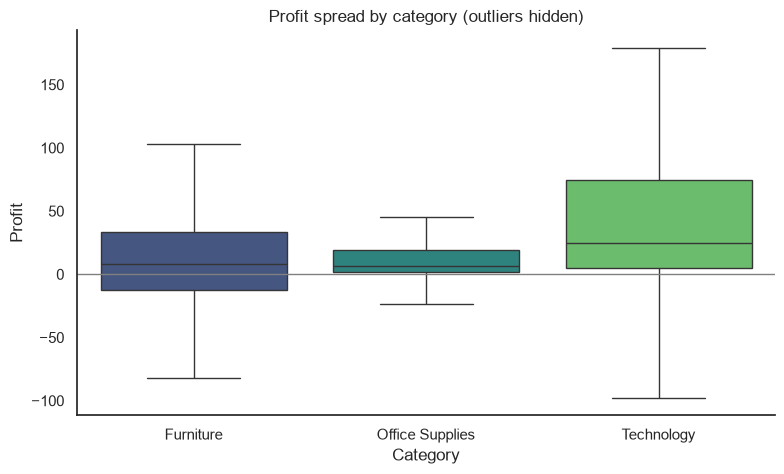

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="Category", y="Profit", hue="Category", palette="viridis",
            legend=False, dodge=False, showfliers=False, ax=ax)
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Profit spread by category (outliers hidden)")
sns.despine()
fig.savefig("outputs/boxplot_category.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.3 Confidence interval bands (95%)

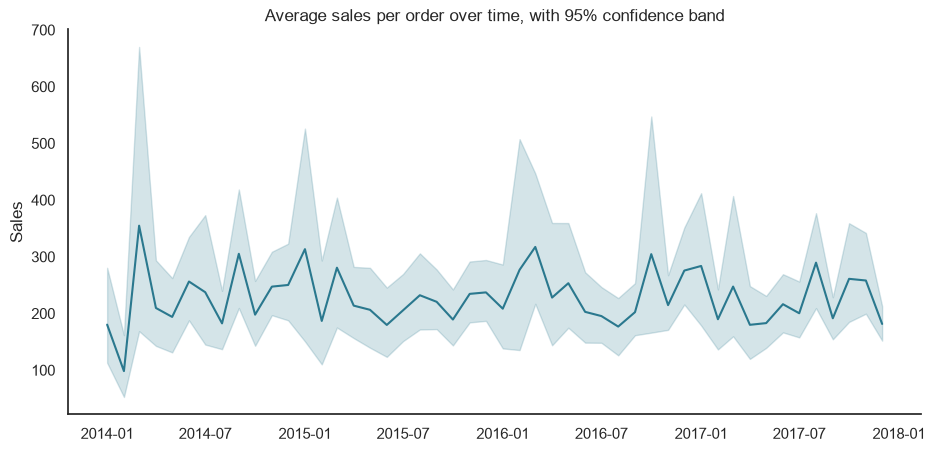

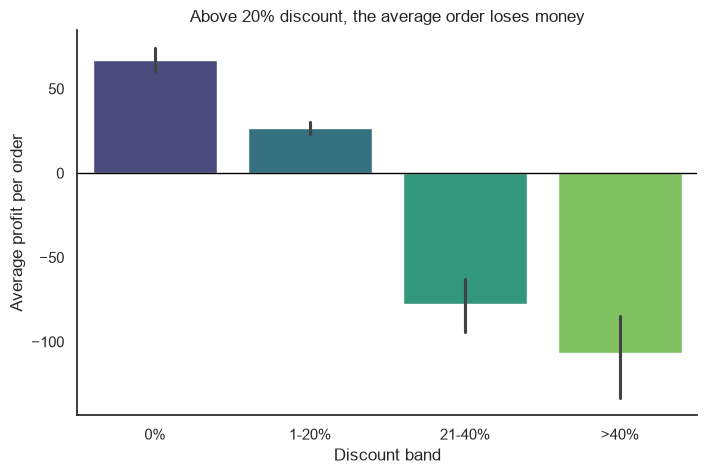

In [6]:
# Line with a 95% confidence band: average sales per order by month
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=df, x="Month_Start", y="Sales", errorbar=("ci", 95), color=BLUE, ax=ax)
ax.set_title("Average sales per order over time, with 95% confidence band")
ax.set_xlabel("")
sns.despine()
fig.savefig("outputs/ci_band_sales.png", dpi=300, bbox_inches="tight")
plt.show()

# Bar chart with error bars; the bar axis includes zero (strict 0-baseline)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df, x="Discount_Band", y="Profit", hue="Discount_Band",
            errorbar=("ci", 95), palette="viridis", legend=False, dodge=False, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Above 20% discount, the average order loses money")
ax.set_xlabel("Discount band")
ax.set_ylabel("Average profit per order")
sns.despine()
fig.savefig("outputs/discount_profit_ci.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. X-Y relationships

### 5.1 Correlation heatmap (diverging palette centered at 0)

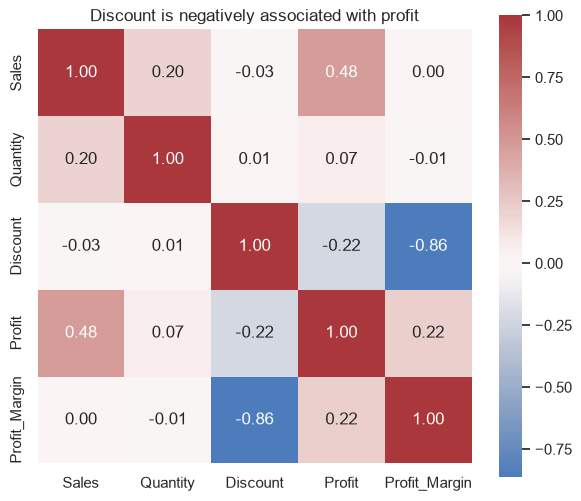

In [7]:
corr = df[["Sales", "Quantity", "Discount", "Profit", "Profit_Margin"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Discount is negatively associated with profit")
fig.savefig("outputs/corr_heatmap.png", dpi=300, bbox_inches="tight")
fig.savefig("outputs/corr_heatmap.svg", bbox_inches="tight")
plt.show()

### 5.2 Interactive bubble chart by sub-category (Plotly)

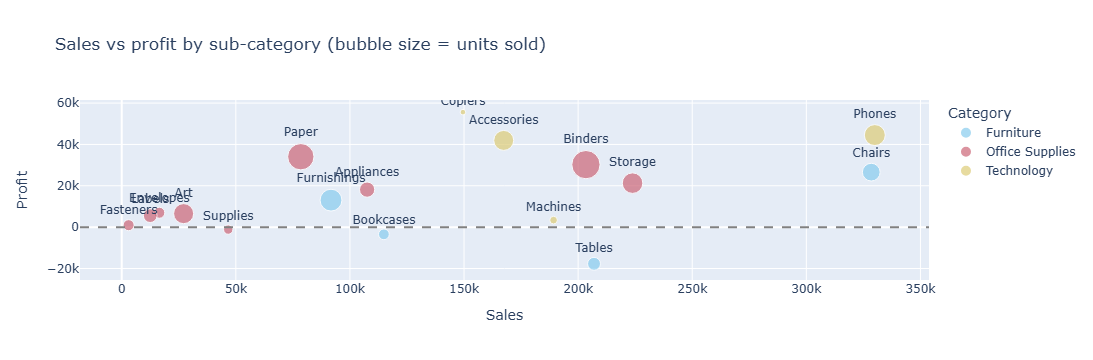

In [8]:
agg = (df.groupby(["Category", "Sub_Category"], as_index=False)
         .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
              Quantity=("Quantity", "sum"), Discount=("Discount", "mean")))

fig = px.scatter(agg, x="Sales", y="Profit", size="Quantity", color="Category",
                 hover_name="Sub_Category", text="Sub_Category",
                 color_discrete_sequence=px.colors.qualitative.Safe,
                 title="Sales vs profit by sub-category (bubble size = units sold)")
fig.add_hline(y=0, line_dash="dash", line_color="gray")
fig.update_traces(textposition="top center")
fig.write_html("outputs/bubble_subcategory.html")
fig.show()

### 5.3 Interactive scatter: discount vs profit

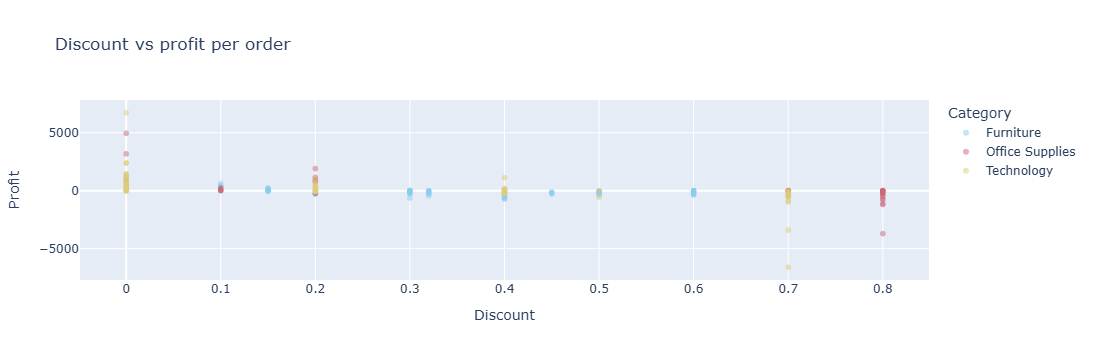

In [9]:
sample = df.sample(3000, random_state=1)  # sample keeps the HTML light
fig2 = px.scatter(sample, x="Discount", y="Profit", color="Category", opacity=0.5,
                  color_discrete_sequence=px.colors.qualitative.Safe,
                  title="Discount vs profit per order")
fig2.write_html("outputs/scatter_discount_profit.html")
fig2.show()

## 6. Key insights for the story

In [10]:
total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
print(f"Total sales: ${total_sales:,.0f} | Total profit: ${total_profit:,.0f} | Margin: {total_profit/total_sales:.1%}")
print(f"Share of orders with negative profit: {(df['Profit'] < 0).mean():.1%}")
print(f"Total losses from those orders: ${df.loc[df['Profit'] < 0, 'Profit'].sum():,.0f}")

print("\nWorst sub-categories (total profit):")
print(df.groupby("Sub_Category")["Profit"].sum().sort_values().head(5).round(0))

print("\nWorst states (total profit):")
print(df.groupby("State")["Profit"].sum().sort_values().head(5).round(0))

print("\nAverage profit by discount band:")
print(df.groupby("Discount_Band", observed=True)["Profit"].mean().round(2))

print("\nProfit margin by region:")
reg = df.groupby("Region")[["Sales", "Profit"]].sum()
print((reg["Profit"] / reg["Sales"]).round(3))

Total sales: $2,297,201 | Total profit: $286,397 | Margin: 12.5%
Share of orders with negative profit: 18.7%
Total losses from those orders: $-156,131

Worst sub-categories (total profit):
Sub_Category
Tables      -17725.0
Bookcases    -3473.0
Supplies     -1189.0
Fasteners      950.0
Machines      3385.0
Name: Profit, dtype: float64

Worst states (total profit):
State
Texas            -25729.0
Ohio             -16971.0
Pennsylvania     -15560.0
Illinois         -12608.0
North Carolina    -7491.0
Name: Profit, dtype: float64

Average profit by discount band:
Discount_Band
0%         66.90
1-20%      26.50
21-40%    -77.86
>40%     -106.71
Name: Profit, dtype: float64

Profit margin by region:
Region
Central    0.079
East       0.135
South      0.119
West       0.149
dtype: float64


## Conclusions
- The business grows, but **~19% of orders lose money**.
- **Discounts above 20%** turn the average order negative.
- **Tables and Bookcases** and several states (Texas, Ohio, Pennsylvania, Illinois) concentrate the losses.
- Recommendation: cap discounts, review pricing for loss-making sub-categories, and investigate the weakest states.